# 03 · The Farmer Trap

A naive "copy the top traders by P&L" leaderboard is full of **farmers** —
wallets that buy near-decided markets at ~99¢ to manufacture flawless win
rates. OrcaLayer's `filter=smart` excludes them. This notebook copies **both**
cohorts and plots their equity curves side by side, so the farmer filter's
value shows up in real P&L instead of a footnote.

Same leaderboard, two filters — apples to apples:
`filter="all"` (raw, farmers included) vs `filter="smart"` (farmers excluded).

> ⚠️ **Informational only — NOT financial advice.** Past performance does not
> predict future results.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

from utils.oc_backtest import leaderboard, blend_cohort

In [2]:
N = 8

raw_cohort = leaderboard(filter="all", limit=N)     # raw top P&L — includes farmers
smart_cohort = leaderboard(filter="smart", limit=N)  # farmer/hedger-filtered

print("RAW top (filter=all):")
for w in raw_cohort:
    print(f"  {w.get('name') or w['wallet'][:12]:20s}  ${w.get('total_pnl', 0):>14,.0f}  WR {w.get('win_rate')}%")
print("\nSMART top (filter=smart):")
for w in smart_cohort:
    print(f"  {w.get('name') or w['wallet'][:12]:20s}  ${w.get('total_pnl', 0):>14,.0f}  WR {w.get('win_rate')}%")

RAW top (filter=all):
  Theo4                 $    22,053,934  WR 81.8%
  Fredi9999             $    16,619,507  WR 60.6%
  swisstony             $    14,878,989  WR 92.2%
  kch123                $    13,000,715  WR 54.7%
  RN1                   $    10,187,106  WR 60.4%
  PrincessCaro          $     6,083,643  WR 81.0%
  KeyTransporter        $     5,711,460  WR 71.4%
  gmanas                $     5,177,401  WR 52.3%

SMART top (filter=smart):
  Theo4                 $    22,053,934  WR 81.8%
  Fredi9999             $    16,619,507  WR 60.6%
  swisstony             $    14,878,989  WR 92.2%
  RN1                   $    10,187,106  WR 60.4%
  PrincessCaro          $     6,083,643  WR 81.0%
  KeyTransporter        $     5,711,460  WR 71.4%
  Substantial-Service   $     4,203,496  WR 55.7%
  Jenzigo               $     4,049,827  WR 90.9%


Backtest and blend each cohort into its own equity curve.

In [3]:
raw_curve, raw_sum = blend_cohort(raw_cohort, limit=500)
smart_curve, smart_sum = blend_cohort(smart_cohort, limit=500)
raw_curve["date"] = pd.to_datetime(raw_curve["last_trade_ts"], unit="s")
smart_curve["date"] = pd.to_datetime(smart_curve["last_trade_ts"], unit="s")

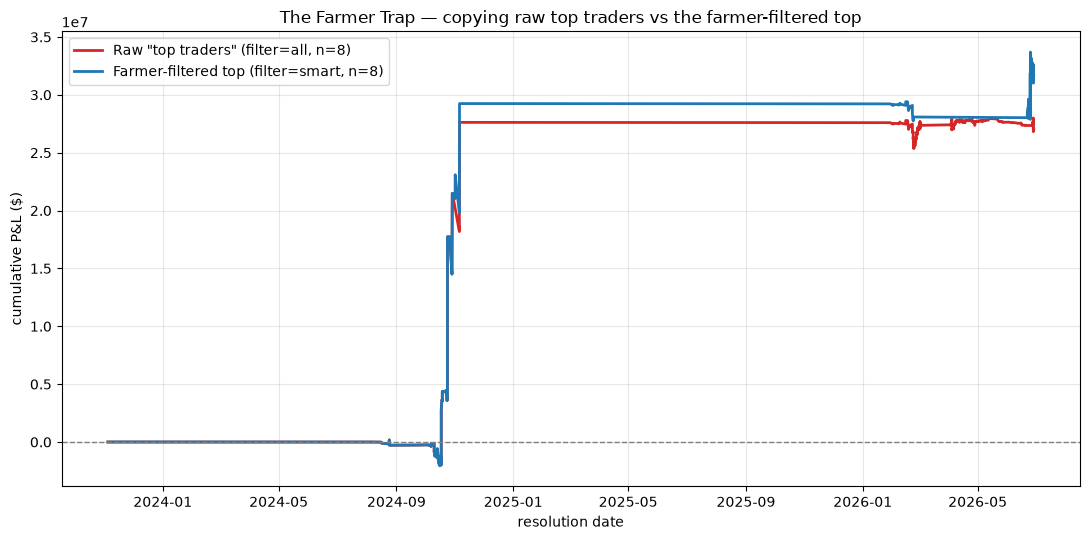

In [4]:
plt.figure(figsize=(11, 5.5))
plt.plot(raw_curve["date"], raw_curve["equity"], lw=2, color="#d62728",
         label=f'Raw "top traders" (filter=all, n={len(raw_cohort)})')
plt.plot(smart_curve["date"], smart_curve["equity"], lw=2, color="#1f77b4",
         label=f"Farmer-filtered top (filter=smart, n={len(smart_cohort)})")
plt.axhline(0, color="grey", lw=1, ls="--")
plt.title("The Farmer Trap — copying raw top traders vs the farmer-filtered top")
plt.xlabel("resolution date")
plt.ylabel("cumulative P&L ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Side-by-side final numbers.

In [5]:
raw_final = float(raw_curve["equity"].iloc[-1]) if not raw_curve.empty else 0.0
smart_final = float(smart_curve["equity"].iloc[-1]) if not smart_curve.empty else 0.0
print(f'Raw "top traders"   final P&L: ${raw_final:,.0f}')
print(f"Farmer-filtered top final P&L: ${smart_final:,.0f}")

Raw "top traders"   final P&L: $27,077,353
Farmer-filtered top final P&L: $31,653,707


A raw P&L leaderboard rewards the farmer's manufactured 99% win rate — but
that "edge" doesn't transfer to a copy-trader, because the farmer was buying
near-certain outcomes for pennies of profit at huge size and tail risk. The
`filter=smart` cohort excludes that pattern up front.

This is exactly why a 99% win rate is a trap, not a signal. See:
- Methodology: https://orcalayer.com/methodology
- "Why a 99% win rate is a trap": https://orcalayer.com/blog

> ⚠️ Informational only — not financial advice.